# **Análise Exploratória de Dados (EDA)**
Exploratory Data Analysis (EDA)


Importando bibliotecas

In [40]:
# from google.colab import drive
# drive.mount('/content/drive')

In [41]:
# Licença: BSD 3 clause

# Importando as bibliotecas

import numpy as np
import pandas as pd

from sklearn import datasets

import random # random library
pallete = ['Accent_r', 'Blues', 'BrBG', 'BrBG_r', 'BuPu']


# 1. Coleta dos dados

In [42]:
# Visualizando o dataset
diabetes_X, diabetes_y = datasets.load_diabetes(return_X_y=True, as_frame=True)

diabetes_X.columns


Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6'], dtype='object')

## 1.1 Descrição do conjunto de dados

* $N = 442$
* Atributos: 10
    * `age`
    * `sex`
    * `bmi` Índice de Massa Corpórea (IMC) - *Body Mass Index* (BMI)
    * `bp` pressão arterial média *blood pressure* (bp)
    * `s1` colesterol total
    * `s2` colesterol LDL
    * `s3` colesterol HDL
    * `s4` colesterol VLDL
    * `s5` triglicerides
    * `s6` glicose
* **Variável dependente**: medida quantitativa de progressão da diabetes

## 1.2 Organização do conjunto de dados

In [43]:
diabetes_X.columns

### --> Criando novos nomes para as colunas
columns = ["Idade","Sexo","IMC","Pressão_arterial","Colesterol_total","Colesterol_LDL","Colesterol_HDL","Colesterol_VLDL","Triglicerides","Glicose"]

### --> Atribui os novos nomes de colunas ao conjunto de dados
diabetes_X.columns = columns


In [44]:
## Agora vamos analisar os valores dos nosso conjunto de dados:

diabetes_X

,Idade,Sexo,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


# 2. Pré-processamento

## 2.1 Tratar valores faltantes (*dados missing*)

In [45]:
diabetes_X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Idade             442 non-null    float64
 1   Sexo              442 non-null    float64
 2   IMC               442 non-null    float64
 3   Pressão_arterial  442 non-null    float64
 4   Colesterol_total  442 non-null    float64
 5   Colesterol_LDL    442 non-null    float64
 6   Colesterol_HDL    442 non-null    float64
 7   Colesterol_VLDL   442 non-null    float64
 8   Triglicerides     442 non-null    float64
 9   Glicose           442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB


In [46]:
###### CRIANDO (FAKE) DADOS FALTANTES PARA EXEMPLIFICAR  ######

# Introduzir dados faltantes nas colunas 'age' e 'bmi'
diabetes_X.loc[:2, ['Idade', 'IMC']] = None

# Mostrar os primeiros registros dos dados com valores faltantes
print(diabetes_X.head())



      Idade      Sexo       IMC  Pressão_arterial  Colesterol_total  \
0       NaN  0.050680       NaN          0.021872         -0.044223   
1       NaN -0.044642       NaN         -0.026328         -0.008449   
2       NaN  0.050680       NaN         -0.005670         -0.045599   
3 -0.089063 -0.044642 -0.011595         -0.036656          0.012191   
4  0.005383 -0.044642 -0.036385          0.021872          0.003935   

   Colesterol_LDL  Colesterol_HDL  Colesterol_VLDL  Triglicerides   Glicose  
0       -0.034821       -0.043401        -0.002592       0.019907 -0.017646  
1       -0.019163        0.074412        -0.039493      -0.068332 -0.092204  
2       -0.034194       -0.032356        -0.002592       0.002861 -0.025930  
3        0.024991       -0.036038         0.034309       0.022688 -0.009362  
4        0.015596        0.008142        -0.002592      -0.031988 -0.046641  


In [47]:
diabetes_X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Idade             439 non-null    float64
 1   Sexo              442 non-null    float64
 2   IMC               439 non-null    float64
 3   Pressão_arterial  442 non-null    float64
 4   Colesterol_total  442 non-null    float64
 5   Colesterol_LDL    442 non-null    float64
 6   Colesterol_HDL    442 non-null    float64
 7   Colesterol_VLDL   442 non-null    float64
 8   Triglicerides     442 non-null    float64
 9   Glicose           442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB


In [48]:
# (1) Verificar se existe algum valor NaN em alguma tabela específica:

diabetes_X['Idade'].isnull().values.any()

np.True_

In [49]:
# (2) Contar quantos valores NaN existem em uma tabela específica:

diabetes_X['Idade'].isnull().sum()

np.int64(3)

In [50]:
# (3) Verificar se existe algum valor NaN no conjunto de dados inteiro:

diabetes_X.isnull().values.any()

np.True_

In [51]:
# (4) Contar quantos valores NaN existem por coluna:

diabetes_X.isnull().sum()

,0
Idade,3
Sexo,0
IMC,3
Pressão_arterial,0
Colesterol_total,0
Colesterol_LDL,0
Colesterol_HDL,0
Colesterol_VLDL,0
Triglicerides,0
Glicose,0


In [52]:
# (5) Contar quantos valores NaN existem por no conjunto de dados inteiro:

diabetes_X.isnull().sum().sum()

np.int64(6)

In [53]:
diabetes_X

,Idade,Sexo,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
0,NaN,0.050680,NaN,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,NaN,-0.044642,NaN,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,NaN,0.050680,NaN,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [54]:
diabetes_X.fillna('TESTE', inplace = False)

diabetes_X.drop(columns = ['Idade'], inplace = False)

diabetes_X.dropna(inplace = False, axis = 1)

diabetes_X.dropna(inplace = False, axis = 0)

,Idade,Sexo,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
0,TESTE,0.050680,TESTE,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,TESTE,-0.044642,TESTE,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,TESTE,0.050680,TESTE,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [55]:
###### RETORNANDO AO CONJUNTO DE DADOS ORIGINAL  ######

diabetes_X, diabetes_y = datasets.load_diabetes(return_X_y=True, as_frame=True)
columns = ["Idade","Sexo","IMC","Pressão_arterial","Colesterol_total","Colesterol_LDL","Colesterol_HDL","Colesterol_VLDL","Triglicerides","Glicose"]
diabetes_X.columns = columns
diabetes_X

,Idade,Sexo,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


## 2.2 Tratar dados categóricos

In [56]:
def modificar_sexo(sexo):
    if sexo > 0:
      return "Masculino"
    else:
      return "Feminino"

# Aplicar a função à coluna 'idade' usando apply
diabetes_X["Sexo"] = diabetes_X["Sexo"].apply(modificar_sexo)

diabetes_X["Sexo"]

,Sexo
0,Masculino
1,Feminino
2,Masculino
3,Feminino
4,Feminino
...,...
437,Masculino
438,Masculino
439,Masculino
440,Feminino


In [57]:
diabetes_X

,Idade,Sexo,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
0,0.038076,Masculino,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,Feminino,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,Masculino,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,Feminino,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,Feminino,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,Masculino,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,Masculino,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,Masculino,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,Feminino,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [58]:
from sklearn.preprocessing import LabelEncoder

# Inicializar o LabelEncoder
label_encoder = LabelEncoder()

# Ajustar e transformar os dados no DataFrame
diabetes_X["Sexo"] = label_encoder.fit_transform(diabetes_X["Sexo"])

# Visualizar o DataFrame resultante
diabetes_X



,Idade,Sexo,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
0,0.038076,1,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,0,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,1,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,0,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,0,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,1,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,1,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,1,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,0,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [59]:
from sklearn.preprocessing import OneHotEncoder

# Inicializar e ajustar o codificador one-hot
encoder = OneHotEncoder(sparse_output=False)
encoded = encoder.fit_transform(diabetes_X["Sexo"].values.reshape(-1, 1))

# Criar um DataFrame com as novas colunas
diabetes_X_encoded = pd.DataFrame(encoded,
                                  columns=encoder.get_feature_names_out(['Sexo']))

print(diabetes_X_encoded)

# Escolher quais colunas manter
colunas_antes = ['Idade', 'Sexo']
colunas_depois = ["IMC","Pressão_arterial","Colesterol_total",
                  "Colesterol_LDL","Colesterol_HDL","Colesterol_VLDL",
                  "Triglicerides","Glicose"]

# Unir os DataFrames ao longo do eixo das colunas
diabetes_X_temp = diabetes_X[colunas_antes].join(diabetes_X_encoded)
diabetes_X = diabetes_X_temp.join(diabetes_X[colunas_depois])

diabetes_X


     Sexo_0  Sexo_1
0       0.0     1.0
1       1.0     0.0
2       0.0     1.0
3       1.0     0.0
4       1.0     0.0
..      ...     ...
437     0.0     1.0
438     0.0     1.0
439     0.0     1.0
440     1.0     0.0
441     1.0     0.0

[442 rows x 2 columns]


,Idade,Sexo,Sexo_0,Sexo_1,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
0,0.038076,1,0.0,1.0,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,0,1.0,0.0,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,1,0.0,1.0,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,0,1.0,0.0,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,0,1.0,0.0,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...,...,...
437,0.041708,1,0.0,1.0,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,1,0.0,1.0,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,1,0.0,1.0,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,0,1.0,0.0,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [60]:
###### RETORNANDO AO CONJUNTO DE DADOS ORIGINAL  ######

diabetes_X, diabetes_y = datasets.load_diabetes(return_X_y=True, as_frame=True)
columns = ["Idade","Sexo","IMC","Pressão_arterial","Colesterol_total","Colesterol_LDL","Colesterol_HDL","Colesterol_VLDL","Triglicerides","Glicose"]
diabetes_X.columns = columns
diabetes_X

,Idade,Sexo,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


# 3. Análise Exploratória de Dados

## 3.1 Descrição estatística

In [61]:
# Importar bibliotecas

import matplotlib.pyplot as plt
import seaborn as sns

In [62]:
diabetes_X.describe()

,Idade,Sexo,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


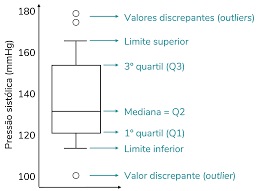

<ipython-input-63-5f24f62ea239>:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(diabetes_X, labels=diabetes_X.columns)


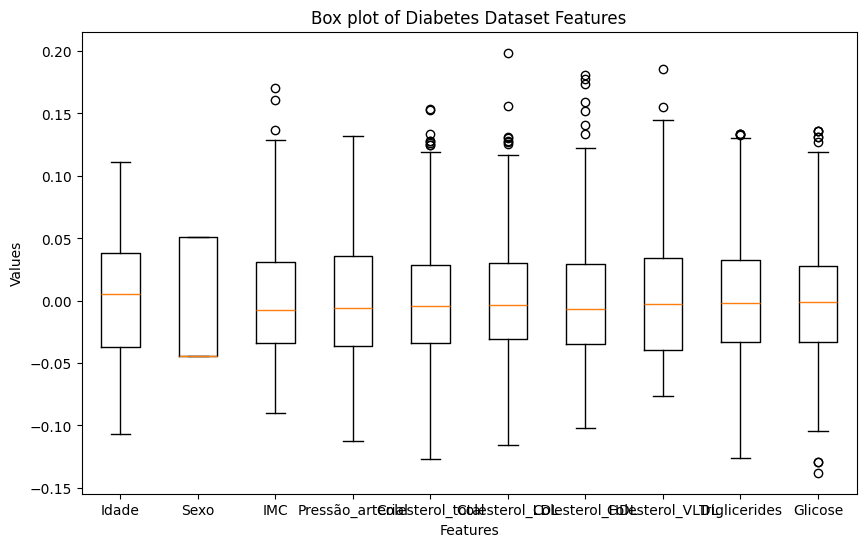

In [63]:
plt.figure(figsize=(10, 6))
plt.boxplot(diabetes_X, labels=diabetes_X.columns)
plt.title('Box plot of Diabetes Dataset Features')
plt.xlabel('Features')
plt.ylabel('Values')
plt.show()


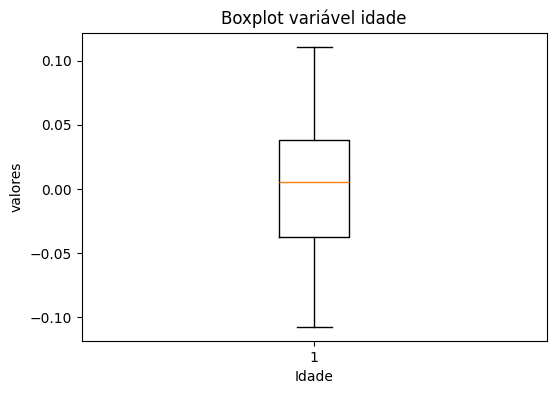

In [64]:
plt.figure(figsize=(6, 4))
plt.boxplot(diabetes_X.iloc[:, 0])
plt.title('Boxplot variável idade')
plt.xlabel('Idade')
plt.ylabel('valores')
plt.show()


In [65]:
corr = diabetes_X.corr()
corr

,Idade,Sexo,IMC,Pressão_arterial,Colesterol_total,Colesterol_LDL,Colesterol_HDL,Colesterol_VLDL,Triglicerides,Glicose
Idade,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731
Sexo,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133
IMC,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680
Pressão_arterial,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430
Colesterol_total,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717
Colesterol_LDL,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600
Colesterol_HDL,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697
Colesterol_VLDL,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212
Triglicerides,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669
Glicose,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000


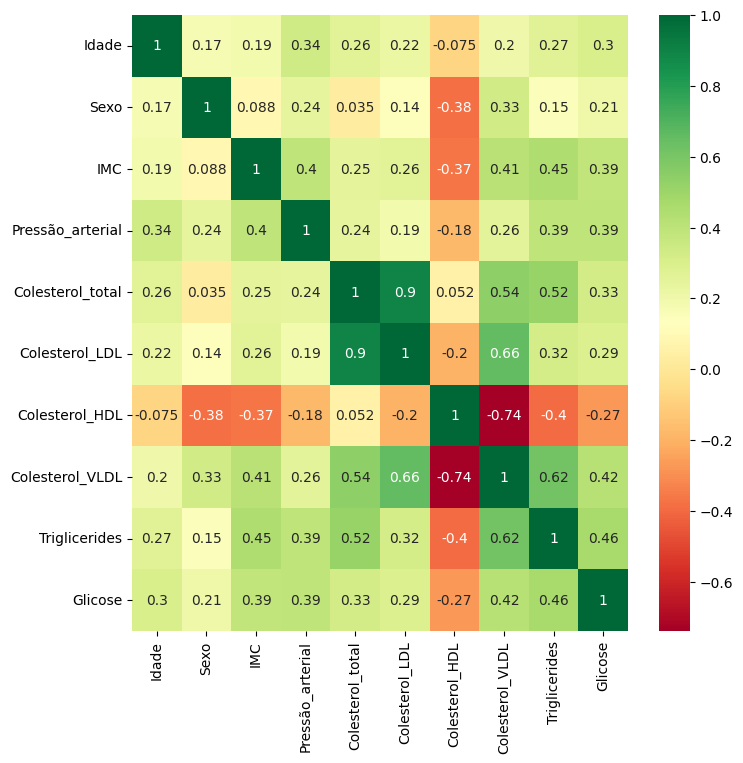

In [66]:
plt.subplots(figsize=(8,8))
sns.heatmap(corr,cmap= 'RdYlGn',annot=True)
plt.show()

In [67]:
sns.pairplot(diabetes_X,hue="Sexo", palette=random.choice(pallete))

Output hidden; open in https://colab.research.google.com to view.

In [68]:
g = sns.pairplot(diabetes_X, hue = "Idade", height = 3, palette=random.choice(pallete))
g.map_diag(sns.histplot)
g.map_offdiag(sns.scatterplot)
g.add_legend()

Output hidden; open in https://colab.research.google.com to view.

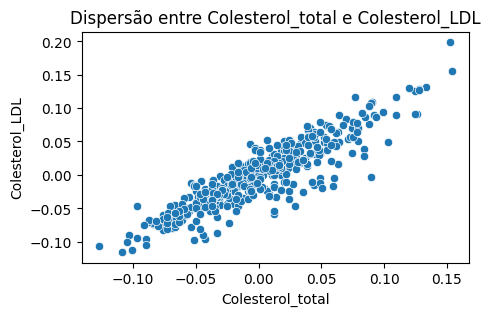

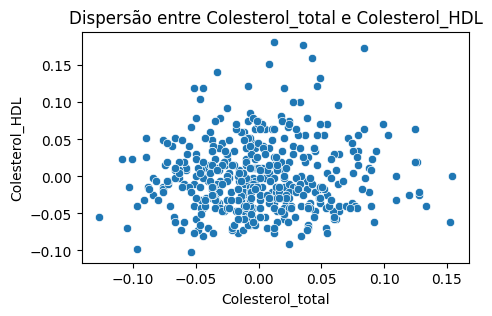

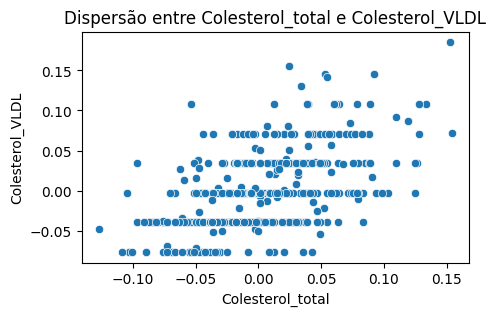

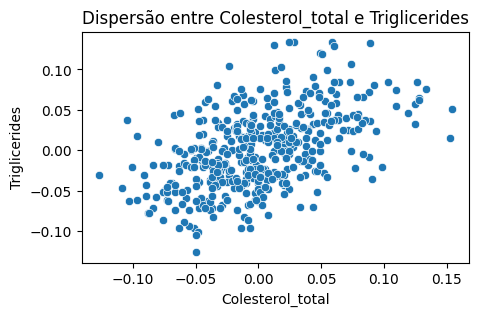

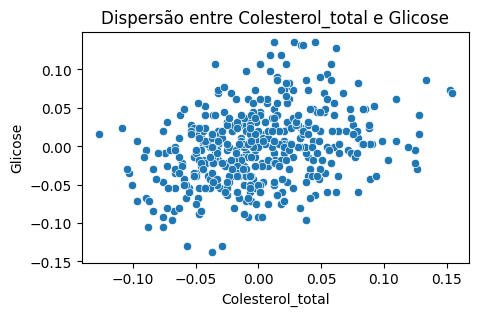

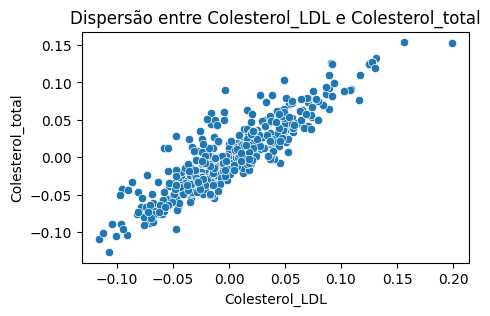

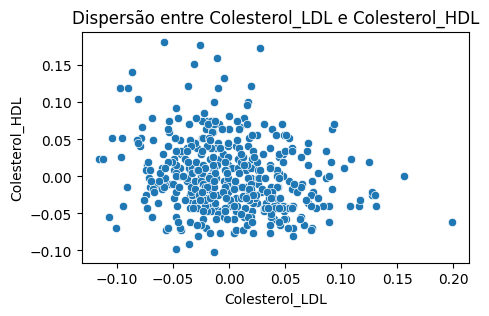

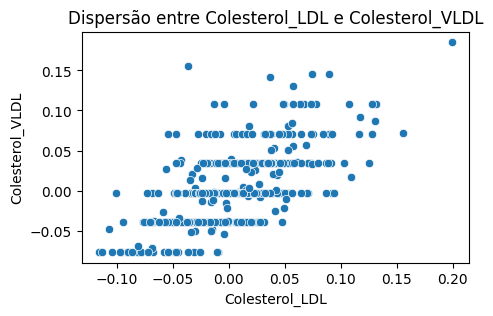

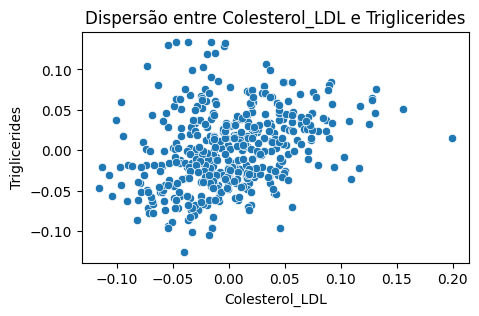

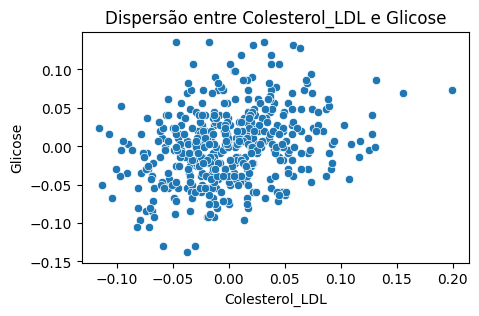

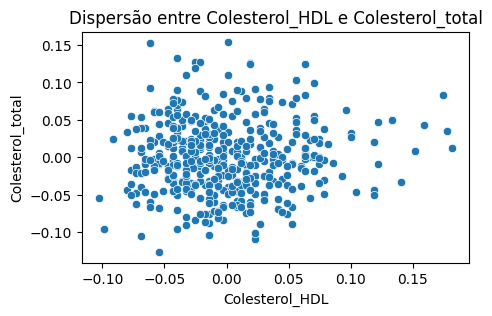

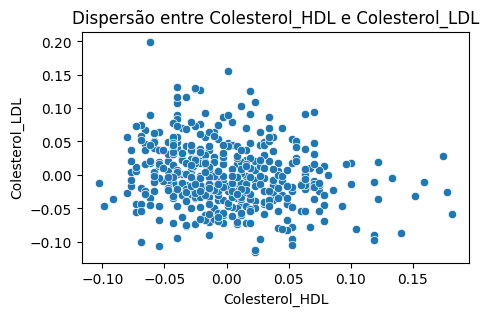

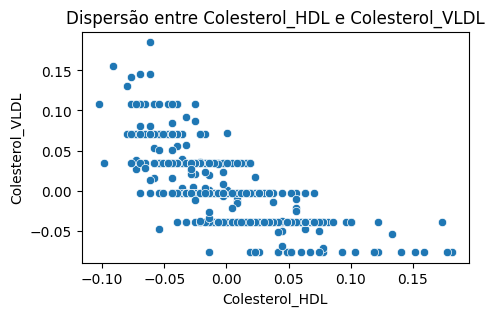

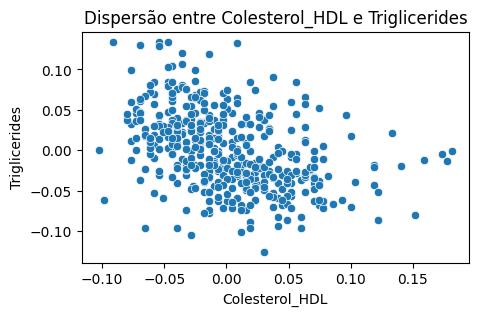

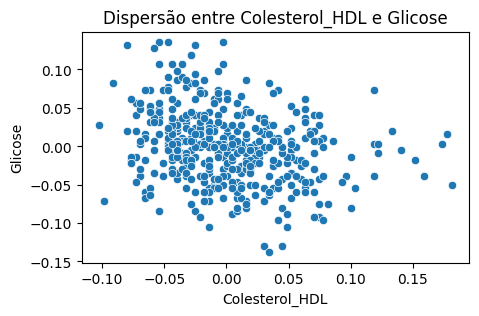

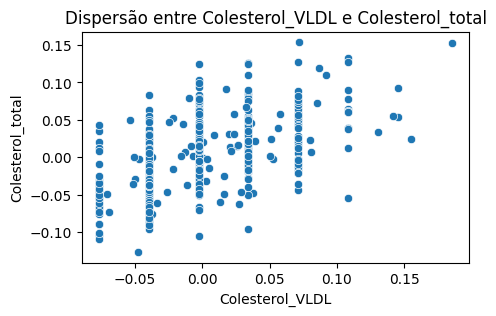

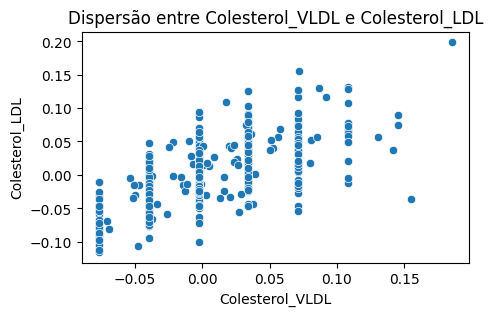

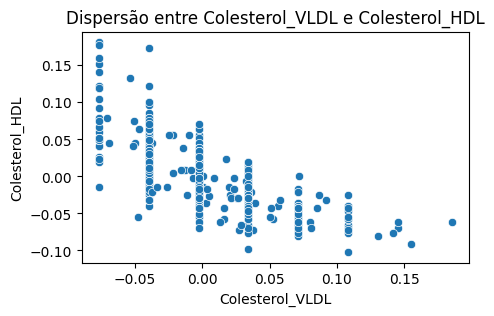

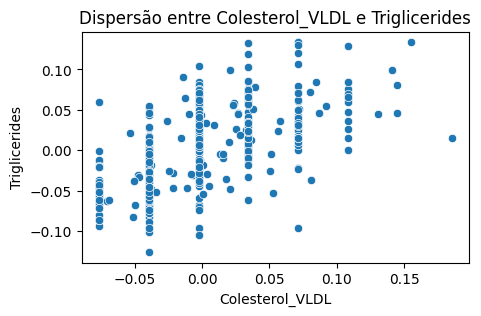

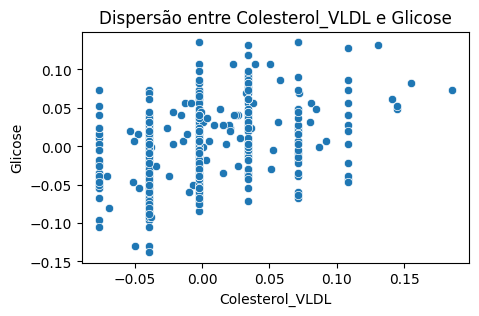

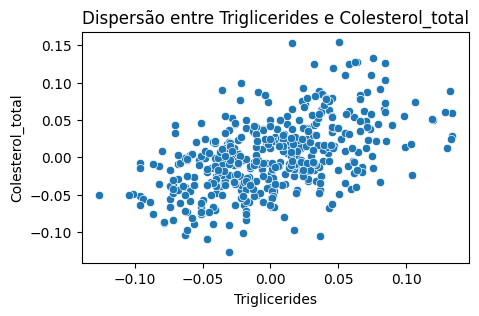

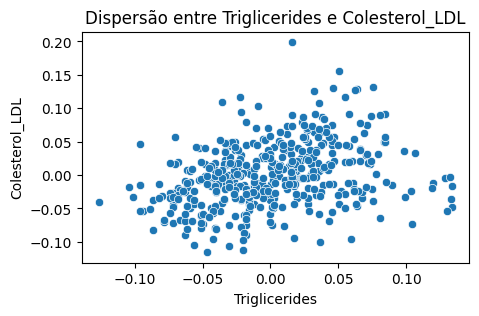

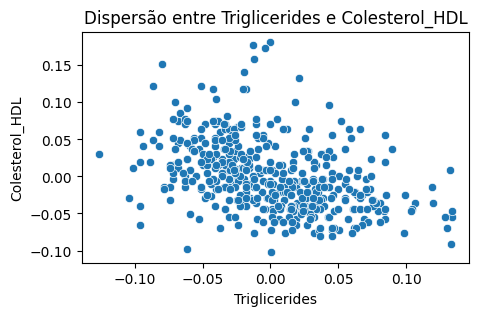

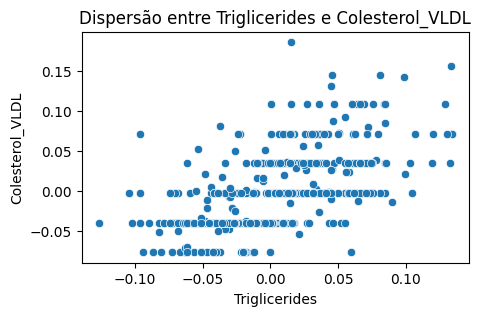

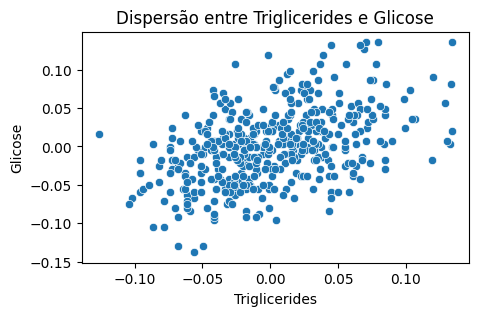

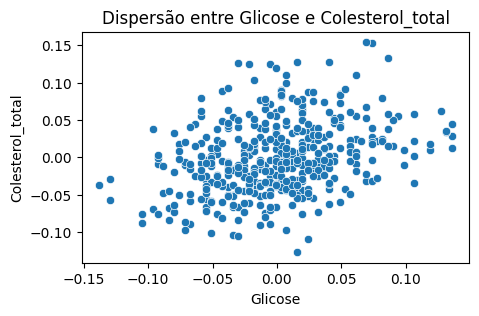

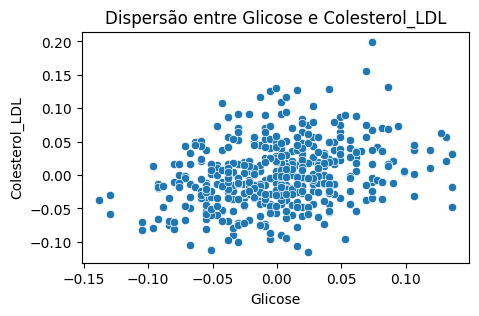

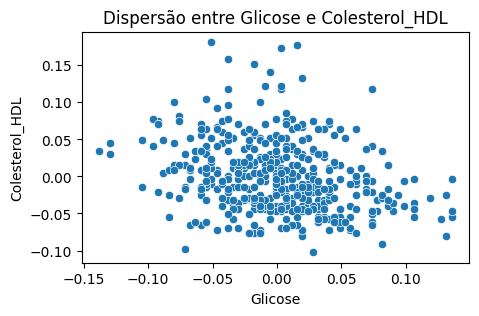

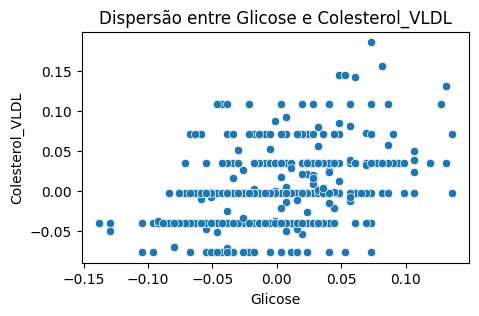

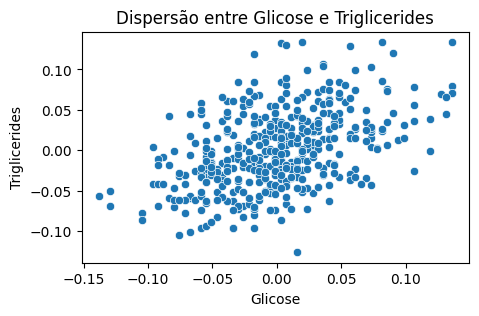

In [69]:
# # Criar DataFrame pandas com os dados e rótulos
# diabetes = pd.DataFrame(data=np.c_[diabetes_X, diabetes_y])


# Análise de dispersão entre variáveis de colesterol, glicose e triglicerides
colesterol_glicose_triglicerides = ["Colesterol_total","Colesterol_LDL",
                                    "Colesterol_HDL","Colesterol_VLDL",
                                    "Triglicerides","Glicose"]

for i, feature1 in enumerate(colesterol_glicose_triglicerides):
    for j, feature2 in enumerate(colesterol_glicose_triglicerides):
        if i != j:
            plt.figure(figsize=(5, 3))

            # Gráfico de dispersão
            sns.scatterplot(data=diabetes_X, x=feature1, y=feature2)
            plt.title(f'Dispersão entre {feature1} e {feature2}')
            plt.xlabel(feature1)
            plt.ylabel(feature2)
            plt.show()


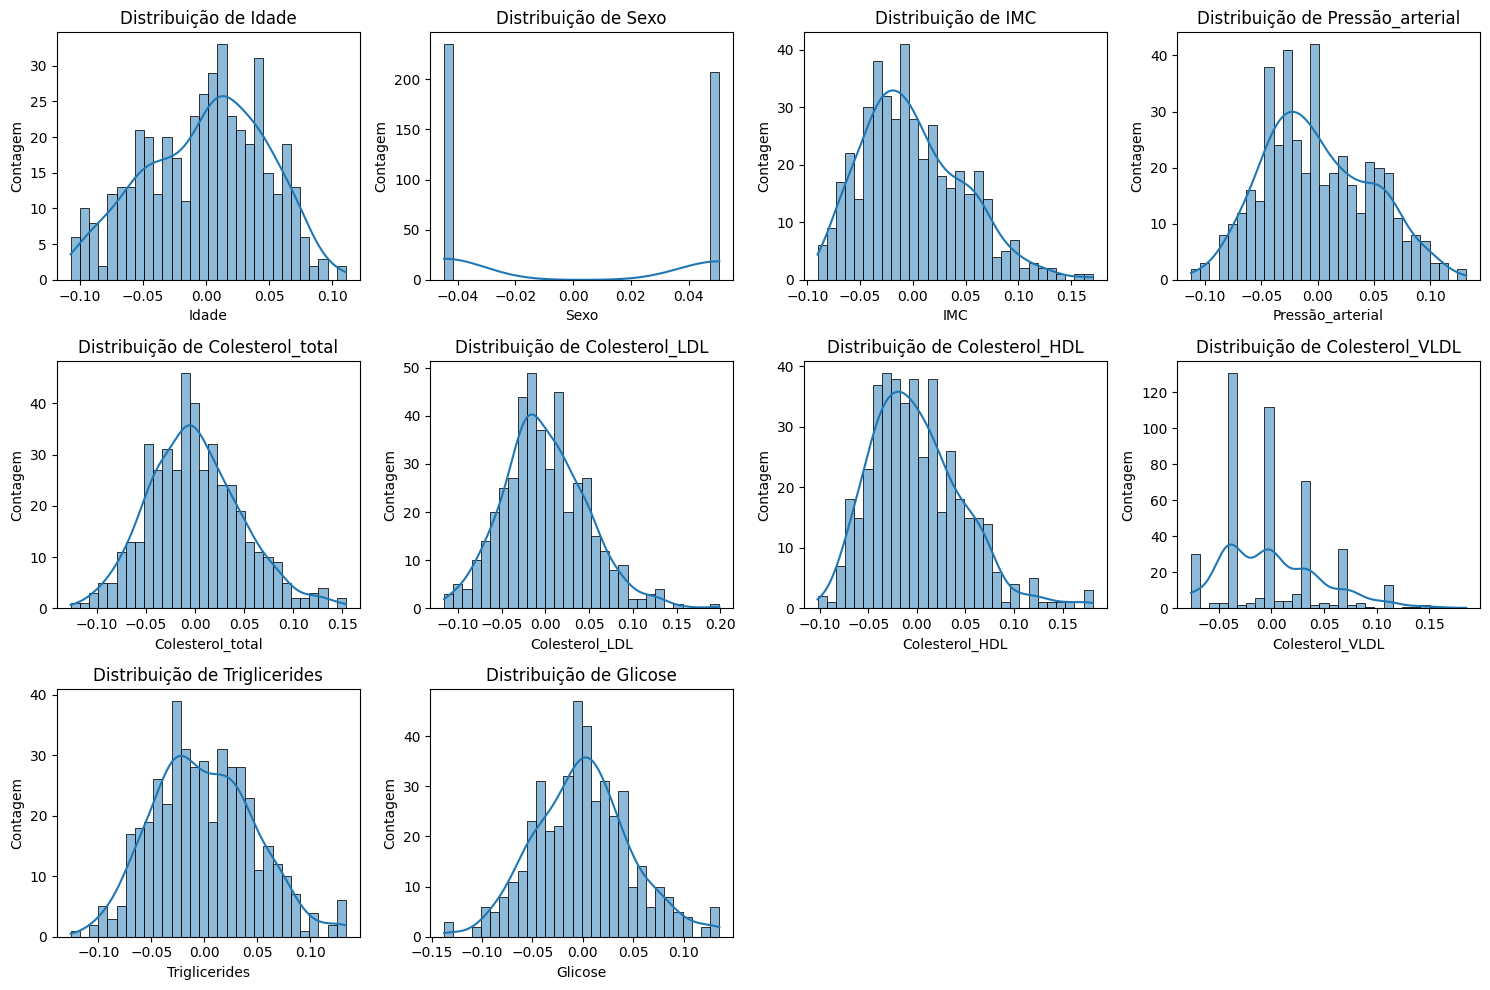

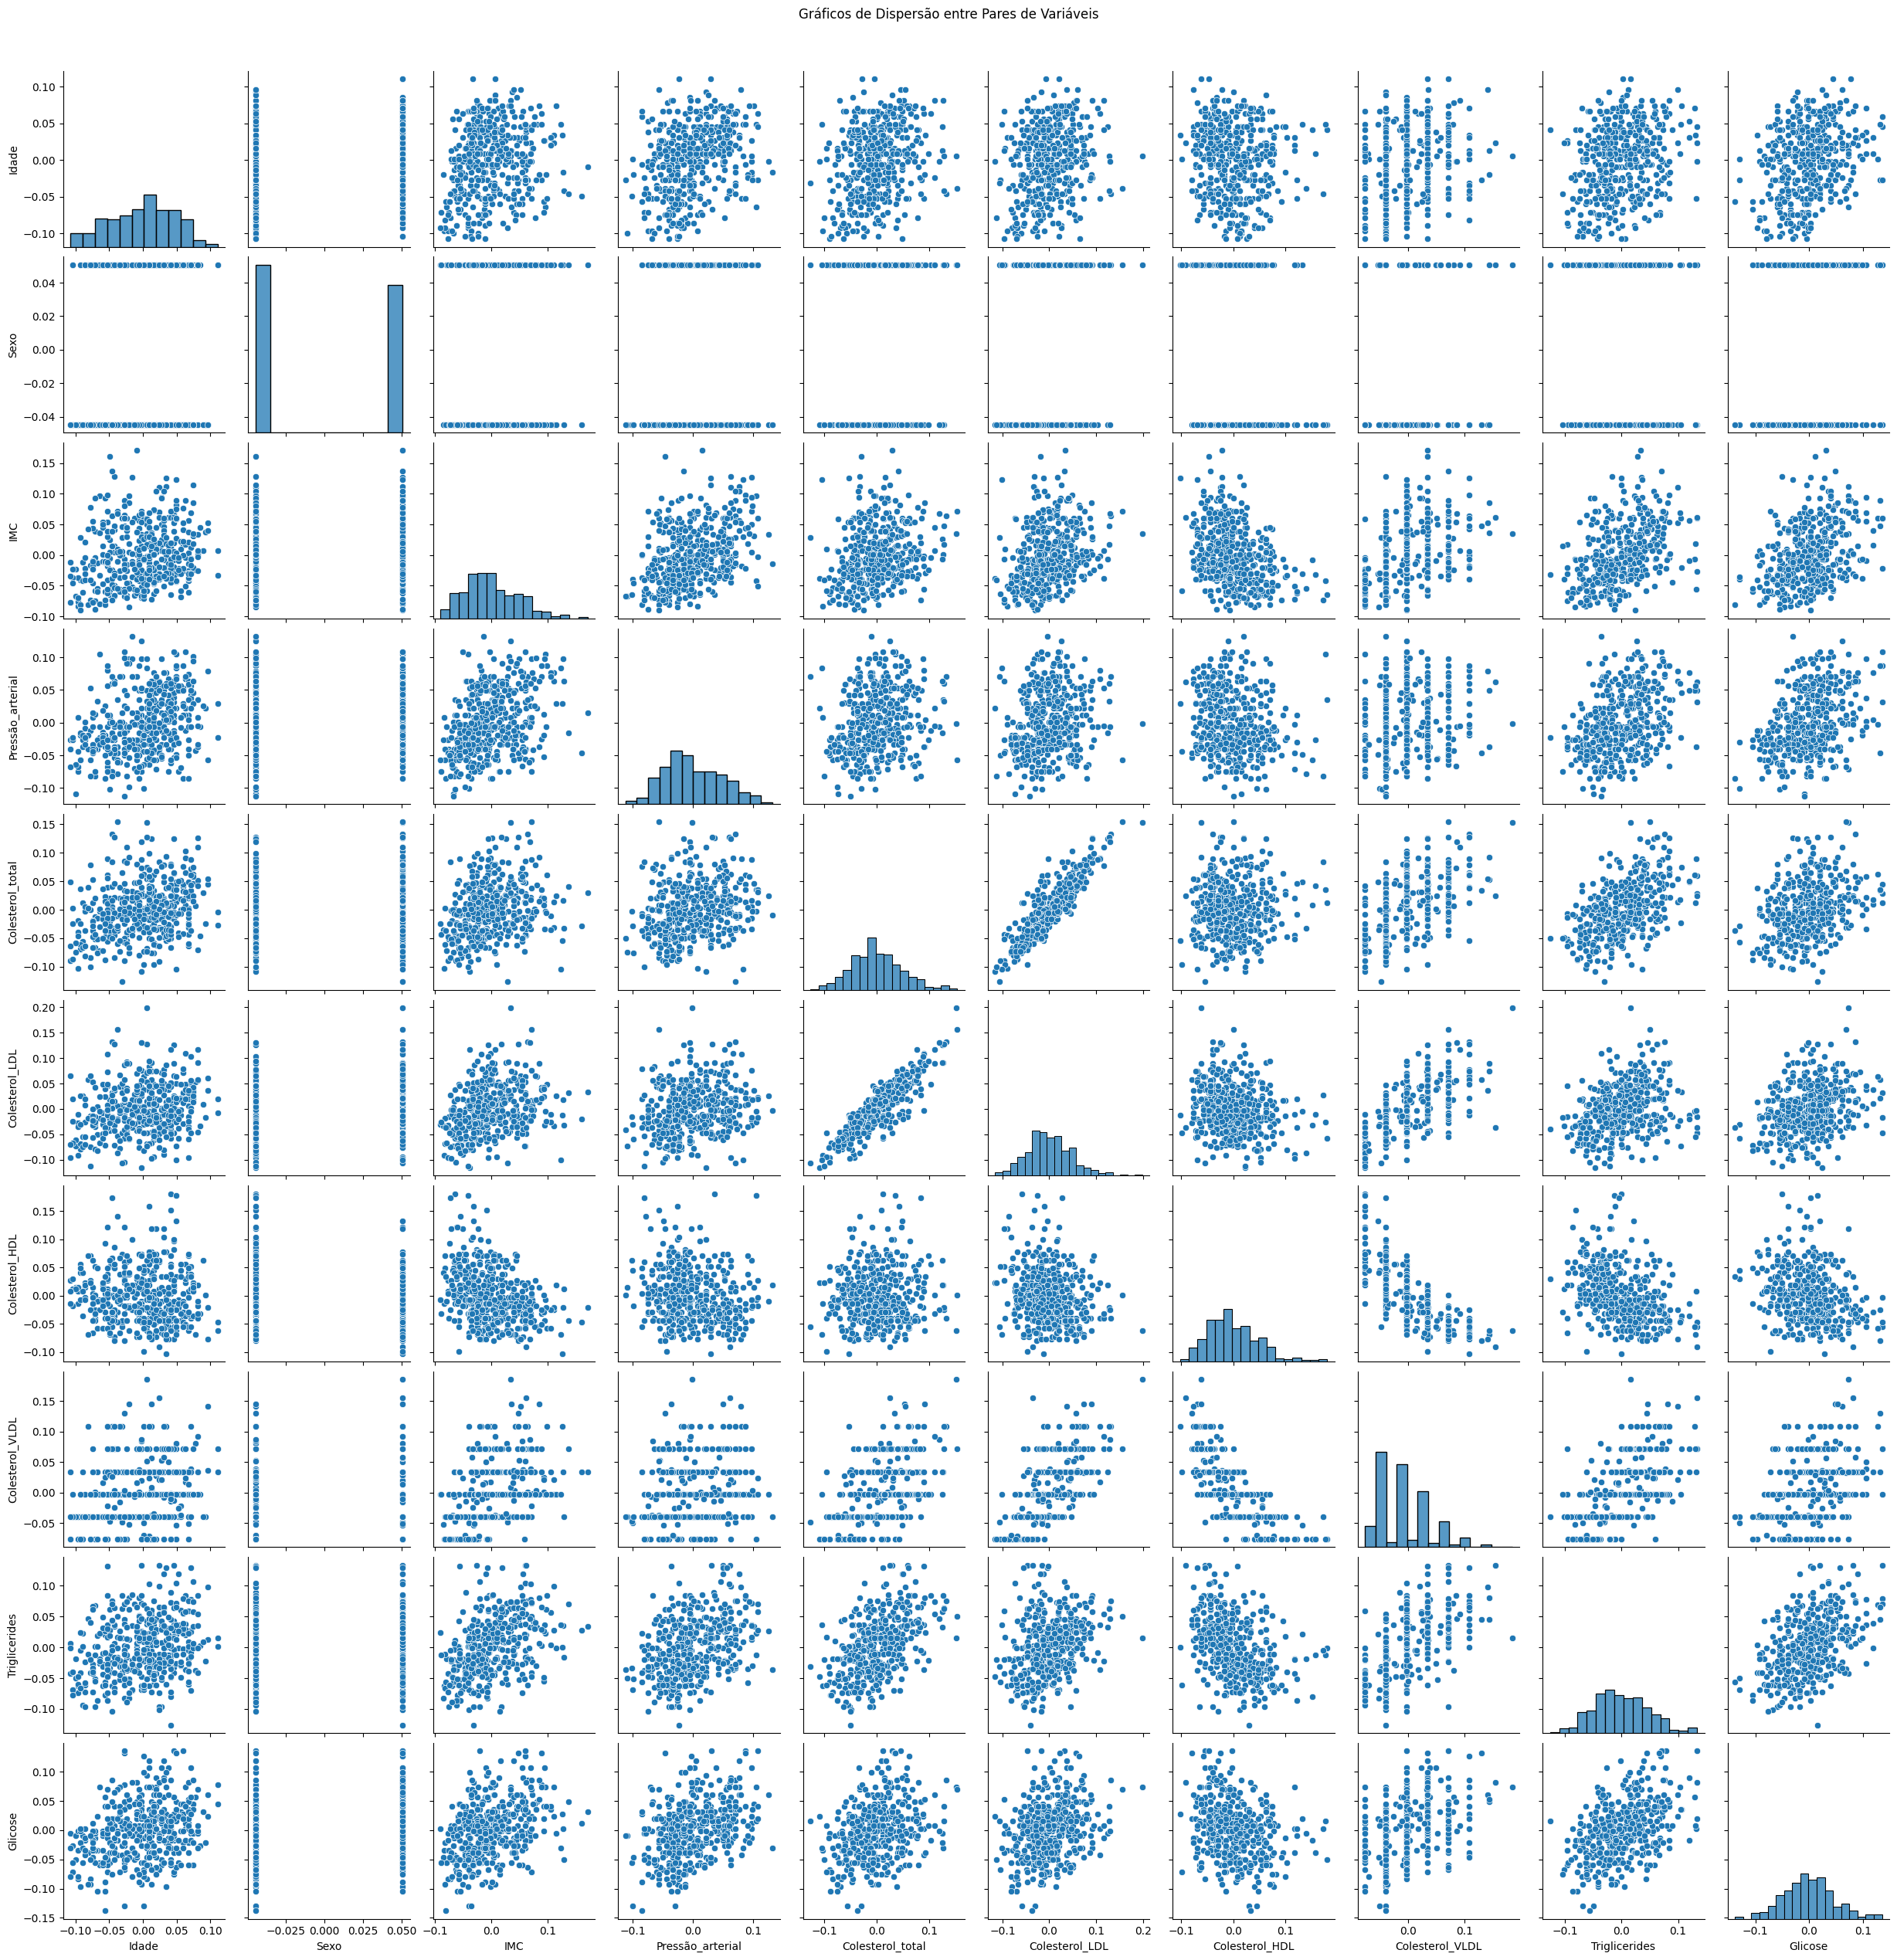

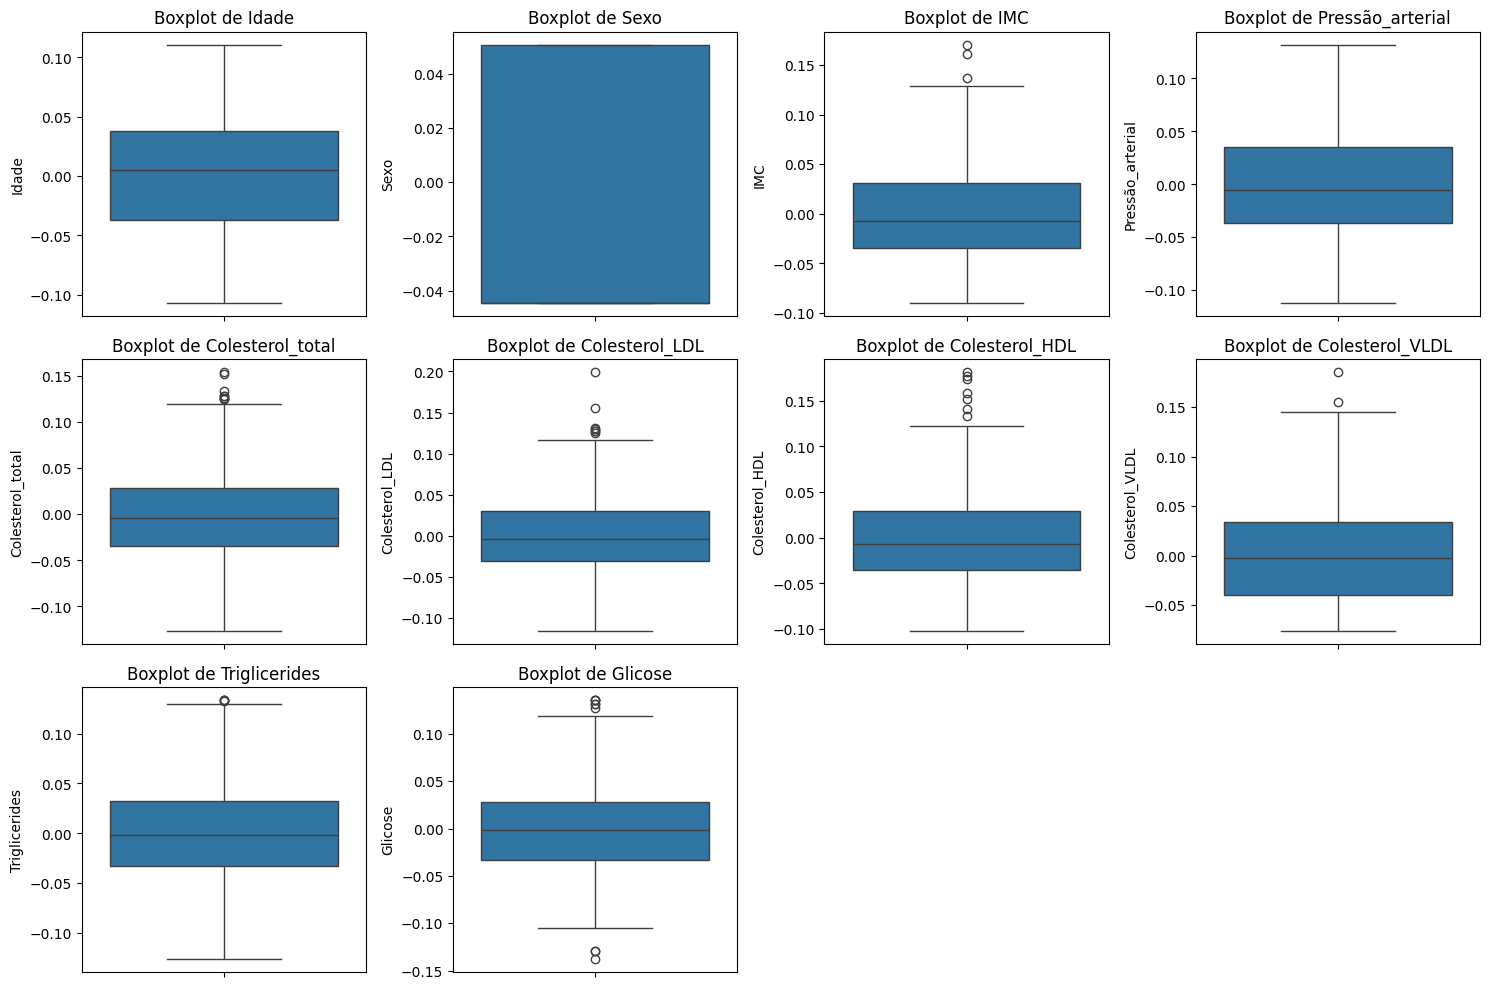

In [70]:
# Visualizar a distribuição de todas as variáveis preditoras
plt.figure(figsize=(15, 10))
for i, feature in enumerate(diabetes_X.columns):  # Não incluir a última coluna (target)
    plt.subplot(3, 4, i + 1)
    sns.histplot(data=diabetes_X, x=feature, bins=30, kde=True)
    plt.title(f'Distribuição de {feature}')
    plt.xlabel(feature)
    plt.ylabel('Contagem')
plt.tight_layout()
plt.show()

# Visualizar gráficos de dispersão entre pares de variáveis
sns.pairplot(diabetes_X)
plt.suptitle("Gráficos de Dispersão entre Pares de Variáveis", y=1.02)
plt.show()

# Visualizar boxplots para cada variável preditora
plt.figure(figsize=(15, 10))
for i, feature in enumerate(diabetes_X.columns):  # Não incluir a última coluna (target)
    plt.subplot(3, 4, i + 1)
    sns.boxplot(data=diabetes_X, y=feature)
    plt.title(f'Boxplot de {feature}')
    plt.ylabel(feature)
plt.tight_layout()
plt.show()


In [71]:
variaveis_quantitativas = list(diabetes_X.columns)

# Análise estatística das variáveis quantitativas
for feature in variaveis_quantitativas:
    print(f"Análise estatística de {feature}:")
    print(f"Média: {diabetes_X[feature].mean()}")
    print(f"Mediana: {diabetes_X[feature].median()}")
    print(f"Desvio Padrão: {diabetes_X[feature].std()}")
    print(f"1º Quartil (Q1): {diabetes_X[feature].quantile(0.25)}")
    print(f"3º Quartil (Q3): {diabetes_X[feature].quantile(0.75)}")
    print("\n")


Análise estatística de Idade:
Média: -2.511816797794472e-19
Mediana: 0.005383060374248237
Desvio Padrão: 0.0476190476190476
1º Quartil (Q1): -0.03729926642522996
3º Quartil (Q3): 0.038075906433423026


Análise estatística de Sexo:
Média: 1.2307902309192911e-17
Mediana: -0.044641636506989144
Desvio Padrão: 0.0476190476190478
1º Quartil (Q1): -0.044641636506989144
3º Quartil (Q3): 0.05068011873981862


Análise estatística de IMC:
Média: -2.2455642172282577e-16
Mediana: -0.007283766209687899
Desvio Padrão: 0.04761904761904761
1º Quartil (Q1): -0.03422906805670789
3º Quartil (Q3): 0.031248015431550695


Análise estatística de Pressão_arterial:
Média: -4.7975700837874414e-17
Mediana: -0.00567042229275739
Desvio Padrão: 0.04761904761904762
1º Quartil (Q1): -0.03665608107540074
3º Quartil (Q3): 0.03564378941743375


Análise estatística de Colesterol_total:
Média: -1.3814992387869595e-17
Mediana: -0.004320865536613489
Desvio Padrão: 0.047619047619047554
1º Quartil (Q1): -0.03424784020248786
3º

## 3.2 Normalização

In [72]:
import numpy as np

# Dados de exemplo
dados = np.array([[10, 2000, 0.003],
                  [40,  0.5,    60],
                  [70,  800, 20000]])



**MinMaxScaler**

Pontos Positivos:

*   Fácil de entender e implementar.
*   Mantém a distribuição relativa dos dados.
*   Útil quando os dados têm distribuição uniforme ou quase uniforme.


Pontos Negativos:

* Sensível a outliers, pois o intervalo é definido pelos valores mínimo e máximo dos dados.
* Não lida bem com dados com distribuição não uniforme.


**Fórmula**:

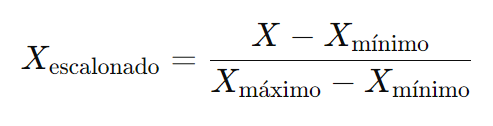


In [73]:
from sklearn.preprocessing import MinMaxScaler

# Inicialize o normalizador
normalizador = MinMaxScaler()

# Ajuste o normalizador aos dados e transforme os dados
dados_normalizados1 = normalizador.fit_transform(dados)

print("Min-Max Normalization:\n", dados_normalizados1)

Min-Max Normalization:
 [[0.         1.         0.        ]
 [0.5        0.         0.00299985]
 [1.         0.39984996 1.        ]]


**StandardScaler**

Pontos Positivos:
* Não é afetado por outliers, já que utiliza a média e o desvio padrão.
* Resulta em uma distribuição normal padrão.
* Útil para algoritmos que assumem que os dados têm distribuição normal, como muitos modelos de regressão.

Pontos Negativos:
* Pode distorcer a distribuição dos dados se estes não seguirem uma distribuição normal.
* A escala pode variar dependendo da presença de outliers.

**Fórmula:**

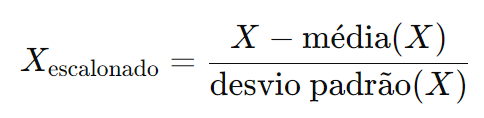

In [74]:
from sklearn.preprocessing import StandardScaler
# Inicialize o normalizador
normalizador = StandardScaler()

# Ajuste o normalizador aos dados e transforme os dados
dados_normalizados2 = normalizador.fit_transform(dados)

print("Z-score Normalization (Standardization):\n", dados_normalizados2)

Z-score Normalization (Standardization):
 [[-1.22474487  1.29786742 -0.71029098]
 [ 0.         -1.13540582 -0.7039178 ]
 [ 1.22474487 -0.1624616   1.41420878]]


**Normalizer L1**

Pontos Positivos:
* Garante que a soma dos valores absolutos seja 1.
* Útil em casos onde a magnitude dos valores é importante.
Pontos Negativos:
* Não leva em consideração a direção dos valores, apenas sua magnitude.
* Não garante que a soma dos quadrados seja 1.

**Fórmula:**

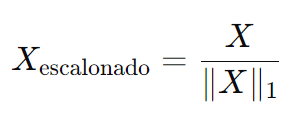

In [75]:
from sklearn.preprocessing import Normalizer

# Inicialize o normalizador
normalizador = Normalizer(norm='l1')

# Ajuste o normalizador aos dados e transforme os dados
dados_normalizados3 = normalizador.fit_transform(dados)

print("L1 Normalization (Least Absolute Deviations):\n", dados_normalizados3)


L1 Normalization (Least Absolute Deviations):
 [[4.97511695e-03 9.95023391e-01 1.49253509e-06]
 [3.98009950e-01 4.97512438e-03 5.97014925e-01]
 [3.35409679e-03 3.83325347e-02 9.58313368e-01]]


**Normalizer L2**

Pontos Positivos:
* Garante que a soma dos quadrados seja 1.
* Preserva a direção e a magnitude dos vetores.

Pontos Negativos:
* Sensível a outliers, pois é baseado na soma dos quadrados dos valores.
* Pode ser computacionalmente mais exigente para grandes conjuntos de dados.


**Fórmula:**

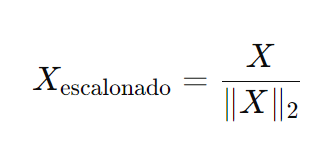

In [76]:
from sklearn.preprocessing import Normalizer

# Inicialize o normalizador
normalizador = Normalizer(norm='l2')

# Ajuste o normalizador aos dados e transforme os dados
dados_normalizados4 = normalizador.fit_transform(dados)

print("L2 Normalization (Least Squares):\n", dados_normalizados4)


L2 Normalization (Least Squares):
 [[4.99993750e-03 9.99987500e-01 1.49998125e-06]
 [5.54686863e-01 6.93358578e-03 8.32030294e-01]
 [3.49718197e-03 3.99677939e-02 9.99194848e-01]]


In [77]:
print("Min-Max Normalization:\n\n", dados_normalizados1)
print("\n Z-score Normalization (Standardization):\n\n", dados_normalizados2)
print("\n L1 Normalization (Least Absolute Deviations):\n\n", dados_normalizados3)
print("\n L2 Normalization (Least Squares):\n\n", dados_normalizados4)

Min-Max Normalization:

 [[0.         1.         0.        ]
 [0.5        0.         0.00299985]
 [1.         0.39984996 1.        ]]

 Z-score Normalization (Standardization):

 [[-1.22474487  1.29786742 -0.71029098]
 [ 0.         -1.13540582 -0.7039178 ]
 [ 1.22474487 -0.1624616   1.41420878]]

 L1 Normalization (Least Absolute Deviations):

 [[4.97511695e-03 9.95023391e-01 1.49253509e-06]
 [3.98009950e-01 4.97512438e-03 5.97014925e-01]
 [3.35409679e-03 3.83325347e-02 9.58313368e-01]]

 L2 Normalization (Least Squares):

 [[4.99993750e-03 9.99987500e-01 1.49998125e-06]
 [5.54686863e-01 6.93358578e-03 8.32030294e-01]
 [3.49718197e-03 3.99677939e-02 9.99194848e-01]]


In [78]:
print('Variável dependente: medida quantitativa de progressão da diabetes: \n\n', diabetes_y)

Variável dependente: medida quantitativa de progressão da diabetes: 

 0      151.0
1       75.0
2      141.0
3      206.0
4      135.0
       ...  
437    178.0
438    104.0
439    132.0
440    220.0
441     57.0
Name: target, Length: 442, dtype: float64
